# Physics-Informed Neural Network for CO₂ Methanation

## 1. Objective and Research Questions

This notebook investigates whether incorporating physical constraints into a neural network improves methane-yield prediction over the studied methanation catalyst.

A Physics-Informed Neural Network (PINN) is developed using:

- experimental methane-yield measurements;
- the reactor molar balance;
- the previously calibrated reversible LHHW kinetic model;
- the inlet boundary condition and stoichiometric limits.

The PINN predicts CO₂ conversion along the catalyst bed. Its training objective combines experimental accuracy with consistency with the governing reactor equation.

### Research questions

1. Can the PINN accurately predict methane yield for unseen experiments?
2. Does incorporating LHHW kinetics improve generalization compared with a conventional neural network?
3. Does the PINN improve prediction in operating regions and temperature ranges absent from training?
4. How closely does the learned conversion profile satisfy the reactor material balance?

The normalized catalyst position is:

$$
s = \frac{W}{W_{\mathrm{total}}}, \qquad 0 \leq s \leq 1
$$

The network predicts CO₂ conversion from position and inlet conditions:

$$
X_{\theta} = f_{\theta}\left(s, T, F_{\mathrm{CO_2},0}, F_{\mathrm{H_2},0}, F_{\mathrm{Ar},0}\right)
$$

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

from scipy.integrate import solve_ivp
from sklearn.cluster import KMeans
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
DEVICE = torch.device('cpu')
DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
sns.set_theme(style='whitegrid', context='notebook')

ROOT = Path.cwd().parent
DATA_PATH = ROOT / 'data' / 'processed' / 'co2_methanation_clean.csv'
LHHW_METRICS_PATH = (
    ROOT / 'reports' / 'physics_based_kinetic_modeling' / 'lhhw_metrics.csv'
)
EXISTING_COMPARISON_PATH = (
    ROOT / 'reports' / 'physics_based_kinetic_modeling'
    / 'three_model_comparison.csv'
)
RESULT_DIR = ROOT / 'reports' / 'pinn_lhhw'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

R = 8.314462618
PRESSURE_BAR = 3.0
CATALYST_MASS_KG = 0.000720
NORMAL_MOLAR_VOLUME_NML_MOL = 22_414.0
T_REF_K = 533.15

## 2. Dataset Preparation


In [3]:
df = pd.read_csv(DATA_PATH)

df['temperature_K'] = df['temperature_C'] + 273.15
df['total_flow_mol_s'] = (
    df['flowrate_NmL_min'] / NORMAL_MOLAR_VOLUME_NML_MOL / 60.0
)
df['co2_in_mol_s'] = df['total_flow_mol_s'] * df['CO2_pct'] / 100.0
df['h2_in_mol_s'] = df['total_flow_mol_s'] * df['H2_pct'] / 100.0
df['ar_in_mol_s'] = df['total_flow_mol_s'] * df['Ar_pct'] / 100.0
df['observed_yield_pct'] = df['CH4_yield_pct'].astype(float)

PHYSICAL_FEATURES = [
    'temperature_K', 'co2_in_mol_s', 'h2_in_mol_s', 'ar_in_mol_s'
]
physical_data = df[
    ['test_id', *PHYSICAL_FEATURES, 'observed_yield_pct']
].copy()

if (physical_data[['co2_in_mol_s', 'h2_in_mol_s']] <= 0).any().any():
    raise ValueError('Reactant molar flows must be positive')
physical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
test_id,215.0,108.567442,62.635974,1.000000,54.500000,109.000000,162.500000,216.000000
temperature_K,215.0,521.256977,16.983023,492.150000,504.150000,523.150000,533.150000,574.150000
co2_in_mol_s,215.0,0.000138,0.000095,0.000029,0.000089,0.000095,0.000136,0.000446
h2_in_mol_s,215.0,0.000492,0.000361,0.000047,0.000279,0.000357,0.000535,0.001785
ar_in_mol_s,215.0,0.000074,0.000152,0.000000,0.000000,0.000000,0.000000,0.000526
observed_yield_pct,215.0,11.447163,11.454941,0.150000,5.315000,8.170000,12.935000,71.320000


### Identical validation splits

KFold, K-Means and temperature splits are reconstructed with the same features and random state as the previous notebooks. Their train/test sizes are checked against the saved LHHW fits.

In [4]:
interpolation_splits = list(
    KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(df)
)

clustering_features = [
    'temperature_C', 'GHSV_h-1', 'H2_CO2_ratio', 'Ar_pct'
]
clustering_scaled = StandardScaler().fit_transform(df[clustering_features])
cluster_labels = KMeans(
    n_clusters=5, n_init=20, random_state=RANDOM_STATE
).fit_predict(clustering_scaled)
region_splits = [
    (
        np.flatnonzero(cluster_labels != cluster),
        np.flatnonzero(cluster_labels == cluster),
    )
    for cluster in sorted(np.unique(cluster_labels))
]
extrapolation_splits = [(
    np.flatnonzero(df['temperature_C'].to_numpy() < 260.0),
    np.flatnonzero(df['temperature_C'].to_numpy() >= 260.0),
)]
protocol_splits = {
    'interpolation': interpolation_splits,
    'region_generalization': region_splits,
    'temperature_extrapolation': extrapolation_splits,
}

lhhw_metrics = pd.read_csv(LHHW_METRICS_PATH)
for protocol, splits in protocol_splits.items():
    saved = lhhw_metrics[lhhw_metrics['protocol'] == protocol].sort_values('split')
    expected_sizes = [(len(train), len(test)) for train, test in splits]
    saved_sizes = list(zip(saved['n_train'], saved['n_test']))
    if expected_sizes != saved_sizes:
        raise ValueError(f'Split mismatch for {protocol}')

pd.DataFrame({
    'protocol': protocol_splits.keys(),
    'number_of_splits': [len(value) for value in protocol_splits.values()],
})

,protocol,number_of_splits
0,interpolation,5
1,region_generalization,5
2,temperature_extrapolation,1


## 3. LHHW Kinetic Model

For each split, the eight LHHW parameters were optimized previously on that split's training observations only. They are loaded and fixed during PINN training.

The PyTorch implementation below mirrors the NumPy LHHW equation while preserving differentiability with respect to conversion:

$$
r=
\frac{k(T)\sqrt{p_{\mathrm{H_2}}p_{\mathrm{CO_2}}}\left(1-Q/K_{\mathrm{eq}}\right)}
{\left(1+K_{\mathrm{OH}}\frac{p_{\mathrm{H_2O}}}{\sqrt{p_{\mathrm{H_2}}}}
+K_{\mathrm{H_2}}\sqrt{p_{\mathrm{H_2}}}+K_{\mathrm{mix}}\sqrt{p_{\mathrm{CO_2}}}\right)^2}
$$

In [5]:
LHHW_PARAMETER_NAMES = [
    'log_k_ref', 'Ea_J_mol',
    'log_K_OH_ref', 'delta_H_OH_J_mol',
    'log_K_H2_ref', 'delta_H_H2_J_mol',
    'log_K_mix_ref', 'delta_H_mix_J_mol',
]


def maximum_conversion_torch(co2_0, h2_0):
    return torch.minimum(torch.ones_like(co2_0), h2_0 / (4.0 * co2_0))


def temperature_constant_torch(log_reference, energy, temperature_K):
    exponent = (
        log_reference
        - energy / R * (1.0 / temperature_K - 1.0 / T_REF_K)
    )
    return torch.exp(torch.clamp(exponent, -100.0, 100.0))


def equilibrium_constant_torch(temperature_K):
    return 137.0 * temperature_K.pow(-3.998) * torch.exp(
        158_700.0 / (R * temperature_K)
    )


def lhhw_rate_torch(X, temperature_K, co2_0, h2_0, ar_0, params):
    (
        log_k_ref, activation_energy,
        log_K_OH_ref, delta_H_OH,
        log_K_H2_ref, delta_H_H2,
        log_K_mix_ref, delta_H_mix,
    ) = params

    co2 = co2_0 * (1.0 - X)
    h2 = h2_0 - 4.0 * co2_0 * X
    ch4 = co2_0 * X
    h2o = 2.0 * co2_0 * X
    total = co2 + h2 + ch4 + h2o + ar_0
    eps = torch.tensor(1e-14, dtype=X.dtype, device=X.device)

    p_co2 = PRESSURE_BAR * co2 / total
    p_h2 = PRESSURE_BAR * h2 / total
    p_ch4 = PRESSURE_BAR * ch4 / total
    p_h2o = PRESSURE_BAR * h2o / total
    p_co2 = torch.clamp(p_co2, min=eps)
    p_h2 = torch.clamp(p_h2, min=eps)
    p_ch4 = torch.clamp(p_ch4, min=0.0)
    p_h2o = torch.clamp(p_h2o, min=0.0)

    kinetic_constant = temperature_constant_torch(
        log_k_ref, activation_energy, temperature_K
    )
    K_OH = temperature_constant_torch(
        log_K_OH_ref, delta_H_OH, temperature_K
    )
    K_H2 = temperature_constant_torch(
        log_K_H2_ref, delta_H_H2, temperature_K
    )
    K_mix = temperature_constant_torch(
        log_K_mix_ref, delta_H_mix, temperature_K
    )
    reaction_quotient = p_h2o.pow(2) * p_ch4 / (p_h2.pow(4) * p_co2)
    reversible_term = (
        1.0 - reaction_quotient / equilibrium_constant_torch(temperature_K)
    )
    denominator = (
        1.0
        + K_OH * p_h2o / torch.sqrt(p_h2)
        + K_H2 * torch.sqrt(p_h2)
        + K_mix * torch.sqrt(p_co2)
    ).pow(2)
    return (
        kinetic_constant * torch.sqrt(p_h2 * p_co2)
        * reversible_term / denominator
    )

In [6]:
# Differentiability and sign checks.
first_row = physical_data.iloc[[0]]
test_conversion = torch.tensor([[0.1]], requires_grad=True)
test_conditions = {
    name: torch.tensor(first_row[[name]].to_numpy())
    for name in PHYSICAL_FEATURES
}
test_params = torch.tensor(
    lhhw_metrics.iloc[0][LHHW_PARAMETER_NAMES].to_numpy(dtype=float)
)
test_rate = lhhw_rate_torch(
    test_conversion,
    test_conditions['temperature_K'],
    test_conditions['co2_in_mol_s'],
    test_conditions['h2_in_mol_s'],
    test_conditions['ar_in_mol_s'],
    test_params,
)
test_rate.sum().backward()
assert torch.isfinite(test_rate).all()
assert test_conversion.grad is not None
{'rate': test_rate.item(), 'drate_dX': test_conversion.grad.item()}

{'rate': 0.010292950705684228, 'drate_dX': -0.0034596712438804814}

## 4. PINN Architecture

A small multilayer perceptron is used:

`5 inputs → Dense(32) → Tanh → Dense(32) → Tanh → Dense(1)`

The model is intentionally small because only 215 experiments are available, with 122–195 training observations depending on the validation split. A larger network would introduce many more parameters and increase overfitting risk. `Tanh` is smooth, which is important for calculating the derivative of conversion with respect to position.

Its output is transformed as

$$
X_{\theta}(s) = s X_{\max} \sigma\left(f_{\theta}\right)
$$

where

$$
X_{\max} = \min\left(1, \frac{F_{\mathrm{H_2},0}}{4F_{\mathrm{CO_2},0}}\right)
$$

This hard transformation enforces the inlet condition and stoichiometric conversion interval exactly.

In [7]:
ARCHITECTURE_NAME = 'small_mlp_32x32'
HIDDEN_SIZE = 32
NUM_HIDDEN_LAYERS = 2
EPOCHS = 1000
LEARNING_RATE = 1e-3
COLLOCATION_POINTS = 10
PHYSICS_WEIGHT = 0.1


class TrainOnlyStandardizer:
    def fit(self, values):
        self.mean = values.mean(axis=0, keepdims=True)
        self.scale = values.std(axis=0, keepdims=True)
        self.scale[self.scale < 1e-14] = 1.0
        return self

    def transform(self, values):
        return (values - self.mean) / self.scale


class PINNLHHW(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Linear(5, HIDDEN_SIZE), nn.Tanh()]
        for _ in range(NUM_HIDDEN_LAYERS - 1):
            layers.extend([nn.Linear(HIDDEN_SIZE, HIDDEN_SIZE), nn.Tanh()])
        layers.append(nn.Linear(HIDDEN_SIZE, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, s, normalized_conditions, maximum_conversion):
        raw_conversion = self.network(
            torch.cat([s, normalized_conditions], dim=1)
        )
        return s * maximum_conversion * torch.sigmoid(raw_conversion)

## 5. Physics-Informed Loss Function

At the reactor outlet, the data loss is

$$
\mathcal{L}_{\mathrm{data}} = \operatorname{MSE}\left(X_{\theta}(1), \frac{Y_{\mathrm{obs}}}{100}\right)
$$

At interior collocation positions, automatic differentiation evaluates

$$
\mathcal{L}_{\mathrm{physics}} = \operatorname{MSE}\left(
\frac{\partial X_{\theta}}{\partial s},
\frac{W_{\mathrm{total}}}{F_{\mathrm{CO_2},0}} r_{\mathrm{LHHW}}\left(X_{\theta}\right)
\right)
$$

The total loss is

$$
\mathcal{L}_{\mathrm{total}} = \mathcal{L}_{\mathrm{data}} + 0.1\,\mathcal{L}_{\mathrm{physics}}
$$

The physics weight is fixed before test evaluation. If it is tuned later, selection must use an internal validation subset of the training data only.

In [8]:
def as_tensor(values, requires_grad=False):
    return torch.tensor(
        values, dtype=DTYPE, device=DEVICE, requires_grad=requires_grad
    )


def split_tensors(row_indices, standardizer):
    values = physical_data.iloc[row_indices][PHYSICAL_FEATURES].to_numpy(float)
    normalized = as_tensor(standardizer.transform(values))
    physical = {name: as_tensor(values[:, [column_index]])
                for column_index, name in enumerate(PHYSICAL_FEATURES)}
    maximum = maximum_conversion_torch(
        physical['co2_in_mol_s'], physical['h2_in_mol_s']
    )
    return normalized, physical, maximum


def calculate_losses(
    model, normalized, physical, maximum, observed_conversion,
    kinetic_params, collocation_positions,
):
    sample_count = normalized.shape[0]

    outlet_s = torch.ones((sample_count, 1), dtype=DTYPE, device=DEVICE)
    outlet_prediction = model(outlet_s, normalized, maximum)
    data_loss = torch.mean((outlet_prediction - observed_conversion) ** 2)

    position_count = collocation_positions.numel()
    physics_s = collocation_positions.repeat(sample_count, 1).reshape(-1, 1)
    physics_s = physics_s.clone().detach().requires_grad_(True)
    repeated_normalized = normalized.repeat_interleave(position_count, dim=0)
    repeated_maximum = maximum.repeat_interleave(position_count, dim=0)
    repeated_physical = {
        name: value.repeat_interleave(position_count, dim=0)
        for name, value in physical.items()
    }
    conversion = model(
        physics_s, repeated_normalized, repeated_maximum
    )
    conversion_derivative = torch.autograd.grad(
        conversion,
        physics_s,
        grad_outputs=torch.ones_like(conversion),
        create_graph=True,
    )[0]
    rate = lhhw_rate_torch(
        conversion,
        repeated_physical['temperature_K'],
        repeated_physical['co2_in_mol_s'],
        repeated_physical['h2_in_mol_s'],
        repeated_physical['ar_in_mol_s'],
        kinetic_params,
    )
    balance_derivative = (
        CATALYST_MASS_KG
        / repeated_physical['co2_in_mol_s']
        * rate
    )
    physics_loss = torch.mean(
        (conversion_derivative - balance_derivative) ** 2
    )
    total_loss = data_loss + PHYSICS_WEIGHT * physics_loss
    return total_loss, data_loss, physics_loss

## 6. PINN Training

Each validation split receives a newly initialized PINN. Only training conditions are used for the data loss, collocation points, normalization and optimization.

In [9]:
def set_reproducible_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def train_pinn(train_indices, kinetic_params, seed=RANDOM_STATE, verbose=False):
    set_reproducible_seed(seed)
    train_values = physical_data.iloc[train_indices][PHYSICAL_FEATURES].to_numpy(float)
    standardizer = TrainOnlyStandardizer().fit(train_values)
    normalized, physical, maximum = split_tensors(train_indices, standardizer)
    observed_conversion = as_tensor(
        physical_data.iloc[train_indices][['observed_yield_pct']].to_numpy(float)
        / 100.0
    )
    kinetic_params_tensor = as_tensor(np.asarray(kinetic_params, dtype=float))

    model = PINNLHHW().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    collocation_positions = torch.linspace(
        0.0, 1.0, COLLOCATION_POINTS + 2,
        dtype=DTYPE, device=DEVICE,
    )[1:-1].reshape(1, -1)

    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        optimizer.zero_grad()
        total_loss, data_loss, physics_loss = calculate_losses(
            model, normalized, physical, maximum, observed_conversion,
            kinetic_params_tensor, collocation_positions,
        )
        if not torch.isfinite(total_loss):
            raise RuntimeError('Non-finite PINN loss')
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
        optimizer.step()

        history.append({
            'epoch': epoch,
            'total_loss': total_loss.item(),
            'data_loss': data_loss.item(),
            'physics_loss': physics_loss.item(),
        })
        if verbose and (epoch == 1 or epoch % 200 == 0):
            print(
                f'epoch={epoch:4d} total={total_loss.item():.3e} '
                f'data={data_loss.item():.3e} physics={physics_loss.item():.3e}'
            )

    return {
        'model': model,
        'standardizer': standardizer,
        'kinetic_params': np.asarray(kinetic_params, dtype=float),
        'history': pd.DataFrame(history),
    }


def predict_pinn(artifact, row_indices, s=1.0):
    model = artifact['model']
    model.eval()
    normalized, _, maximum = split_tensors(
        row_indices, artifact['standardizer']
    )
    positions = torch.full(
        (len(row_indices), 1), float(s), dtype=DTYPE, device=DEVICE
    )
    with torch.no_grad():
        conversion = model(positions, normalized, maximum)
    return conversion.cpu().numpy().ravel()

## 7–9. Interpolation, Regional Generalization and Temperature Extrapolation

Eleven PINNs are trained using the same test indices as all previous models. The corresponding LHHW parameter vector is loaded for each training split.

In [10]:
def kinetic_params_for_split(protocol, split_id):
    selected = lhhw_metrics[
        (lhhw_metrics['protocol'] == protocol)
        & (lhhw_metrics['split'] == split_id)
    ]
    if len(selected) != 1:
        raise ValueError(f'Missing LHHW parameters for {protocol}, split {split_id}')
    return selected.iloc[0][LHHW_PARAMETER_NAMES].to_numpy(dtype=float)


def evaluate_pinn_protocol(protocol, splits):
    metric_rows = []
    prediction_frames = []
    artifacts = {}

    for split_id, (train_indices, test_indices) in enumerate(splits):
        print(f'PINN {protocol}: split {split_id + 1}/{len(splits)}')
        kinetic_params = kinetic_params_for_split(protocol, split_id)
        artifact = train_pinn(
            train_indices, kinetic_params,
            seed=RANDOM_STATE + split_id,
        )
        predicted = 100.0 * predict_pinn(artifact, test_indices)
        observed = physical_data.iloc[test_indices][
            'observed_yield_pct'
        ].to_numpy()
        artifacts[split_id] = artifact
        metric_rows.append({
            'architecture': ARCHITECTURE_NAME,
            'protocol': protocol,
            'split': split_id,
            'n_train': len(train_indices),
            'n_test': len(test_indices),
            'RMSE': root_mean_squared_error(observed, predicted),
            'final_data_loss': artifact['history']['data_loss'].iloc[-1],
            'final_physics_loss': artifact['history']['physics_loss'].iloc[-1],
        })
        prediction_frames.append(pd.DataFrame({
            'protocol': protocol,
            'split': split_id,
            'row_index': test_indices,
            'temperature_C': df.iloc[test_indices]['temperature_C'].to_numpy(),
            'observed': observed,
            'predicted': predicted,
            'residual': predicted - observed,
        }))

    return (
        pd.DataFrame(metric_rows),
        pd.concat(prediction_frames, ignore_index=True),
        artifacts,
    )


pinn_results = {
    protocol: evaluate_pinn_protocol(protocol, splits)
    for protocol, splits in protocol_splits.items()
}
pinn_metrics = pd.concat(
    [result[0] for result in pinn_results.values()], ignore_index=True
)
pinn_predictions = pd.concat(
    [result[1] for result in pinn_results.values()], ignore_index=True
)
trained_artifacts = {
    protocol: result[2] for protocol, result in pinn_results.items()
}
pinn_summary = pinn_metrics.groupby('protocol', as_index=False).agg(
    RMSE_mean=('RMSE', 'mean'),
    RMSE_std=('RMSE', 'std'),
    n_splits=('RMSE', 'count'),
)
pinn_summary['RMSE_std'] = pinn_summary['RMSE_std'].fillna(0.0)
pinn_summary.round(3)

PINN interpolation: split 1/5
PINN interpolation: split 2/5
PINN interpolation: split 3/5
PINN interpolation: split 4/5
PINN interpolation: split 5/5
PINN region_generalization: split 1/5
PINN region_generalization: split 2/5
PINN region_generalization: split 3/5
PINN region_generalization: split 4/5
PINN region_generalization: split 5/5
PINN temperature_extrapolation: split 1/1


,protocol,RMSE_mean,RMSE_std,n_splits
0,interpolation,1.576,0.318,5
1,region_generalization,3.999,1.679,5
2,temperature_extrapolation,4.098,0.000,1


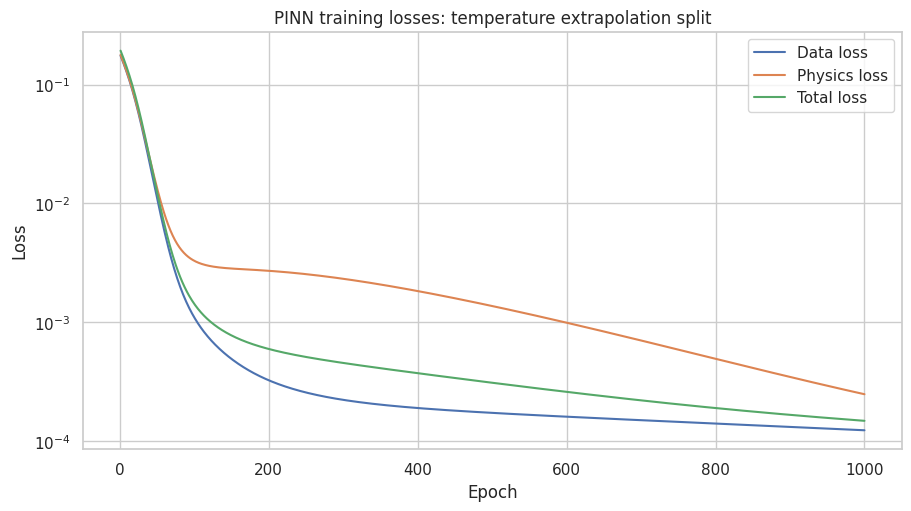

In [11]:
extrapolation_history = trained_artifacts[
    'temperature_extrapolation'
][0]['history']
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.semilogy(extrapolation_history['epoch'], extrapolation_history['data_loss'],
            label='Data loss')
ax.semilogy(extrapolation_history['epoch'], extrapolation_history['physics_loss'],
            label='Physics loss')
ax.semilogy(extrapolation_history['epoch'], extrapolation_history['total_loss'],
            label='Total loss')
ax.set(title='PINN training losses: temperature extrapolation split',
       xlabel='Epoch', ylabel='Loss')
ax.legend()
fig.savefig(RESULT_DIR / 'training_losses.png', dpi=180, bbox_inches='tight')
plt.show()

## 10. Comparison with NN, Power Law and LHHW

RMSE is expressed in methane-yield percentage points and aggregated using the same mean-of-split method.

In [12]:
existing_comparison = pd.read_csv(EXISTING_COMPARISON_PATH)
pinn_scores = pinn_summary.set_index('protocol')['RMSE_mean']
four_model_comparison = existing_comparison.copy()
four_model_comparison['PINN-LHHW'] = [
    pinn_scores['interpolation'],
    pinn_scores['region_generalization'],
    pinn_scores['temperature_extrapolation'],
]
four_model_comparison.round(3)

,Scenario,Neural Network,Reversible Power Law,LHHW,PINN-LHHW
0,Interpolation,1.754,1.628,1.132,1.576
1,Regional generalization,6.264,2.680,1.630,3.999
2,Temperature extrapolation,10.417,3.607,3.138,4.098


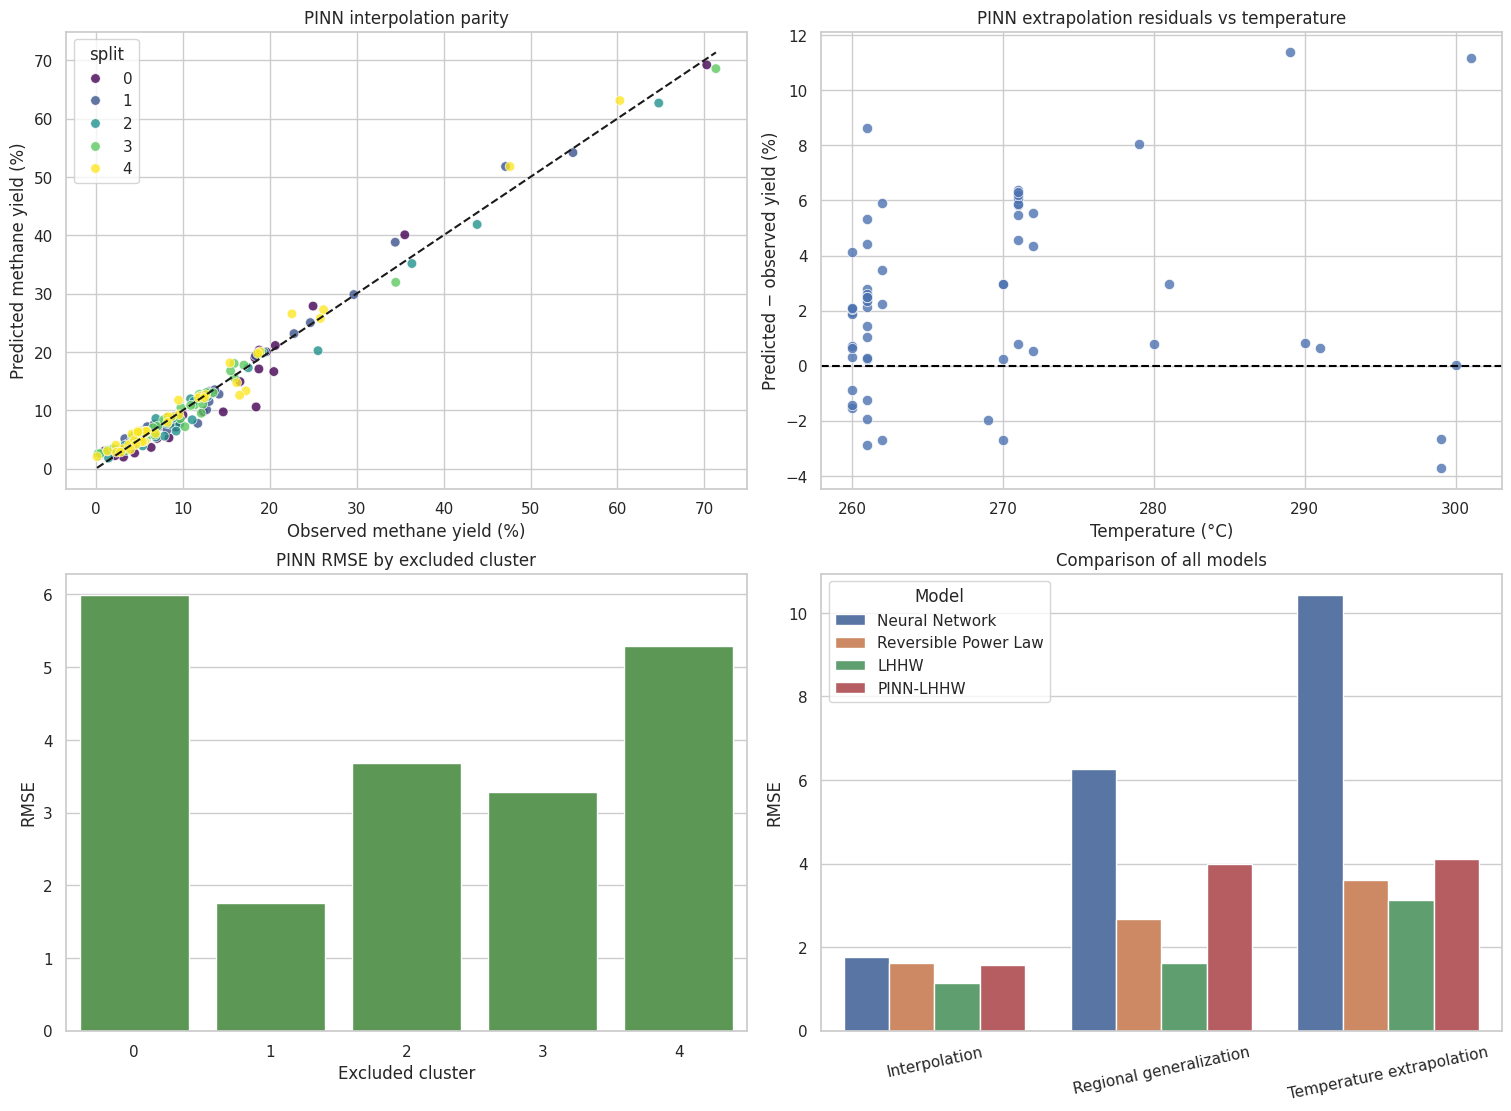

In [13]:
interpolation_predictions = pinn_predictions[
    pinn_predictions['protocol'] == 'interpolation'
]
regional_metrics = pinn_metrics[
    pinn_metrics['protocol'] == 'region_generalization'
]
extrapolation_predictions = pinn_predictions[
    pinn_predictions['protocol'] == 'temperature_extrapolation'
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)
parity_min = min(
    interpolation_predictions['observed'].min(),
    interpolation_predictions['predicted'].min(),
)
parity_max = max(
    interpolation_predictions['observed'].max(),
    interpolation_predictions['predicted'].max(),
)
sns.scatterplot(
    data=interpolation_predictions, x='observed', y='predicted',
    hue='split', palette='viridis', s=48, alpha=0.8, ax=axes[0, 0]
)
axes[0, 0].plot([parity_min, parity_max], [parity_min, parity_max], '--k')
axes[0, 0].set(
    title='PINN interpolation parity',
    xlabel='Observed methane yield (%)', ylabel='Predicted methane yield (%)',
)

sns.scatterplot(
    data=extrapolation_predictions, x='temperature_C', y='residual',
    s=55, alpha=0.8, ax=axes[0, 1]
)
axes[0, 1].axhline(0.0, linestyle='--', color='black')
axes[0, 1].set(
    title='PINN extrapolation residuals vs temperature',
    xlabel='Temperature (°C)', ylabel='Predicted − observed yield (%)',
)

sns.barplot(
    data=regional_metrics, x='split', y='RMSE',
    color='#54A24B', ax=axes[1, 0]
)
axes[1, 0].set(
    title='PINN RMSE by excluded cluster',
    xlabel='Excluded cluster', ylabel='RMSE',
)

comparison_long = four_model_comparison.melt(
    id_vars='Scenario', var_name='Model', value_name='RMSE'
)
sns.barplot(
    data=comparison_long, x='Scenario', y='RMSE', hue='Model',
    ax=axes[1, 1]
)
axes[1, 1].set(
    title='Comparison of all models', xlabel='', ylabel='RMSE'
)
axes[1, 1].tick_params(axis='x', rotation=12)

fig.savefig(RESULT_DIR / 'predictive_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()

## 11. Physical Consistency Analysis

Conversion profiles predicted by the temperature-extrapolation PINN are compared with direct LHHW integration. These internal profiles are two model predictions, not intermediate experimental measurements.

Physics residuals are evaluated on a denser position grid than the ten collocation points used during training.

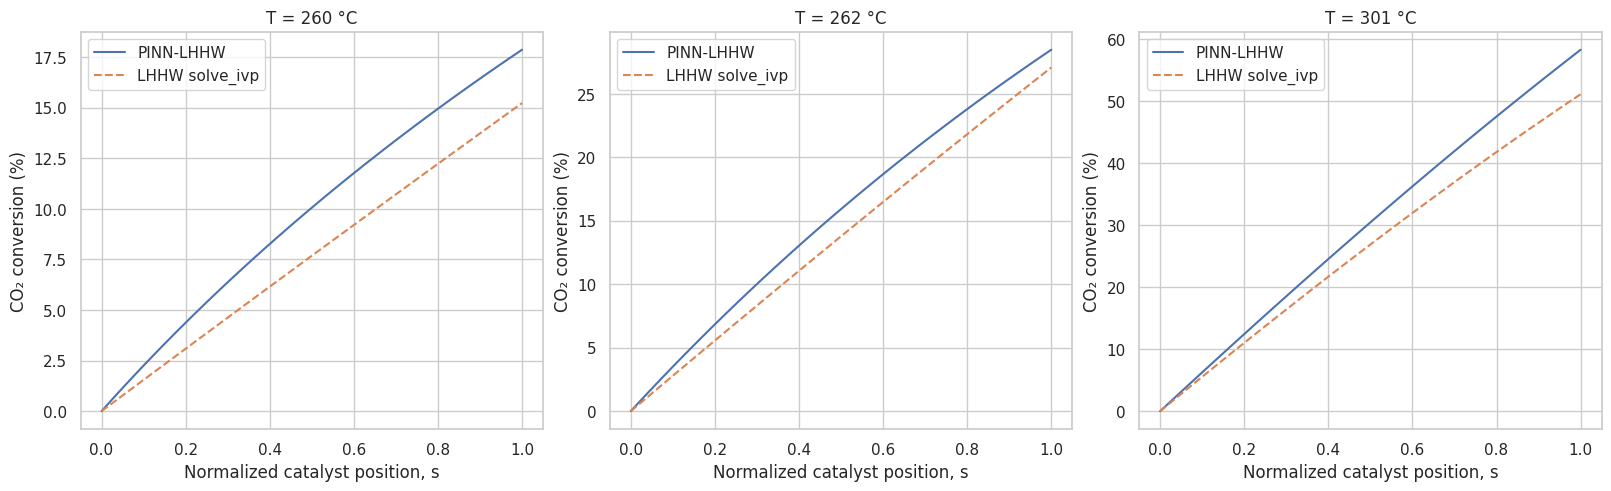

In [14]:
def lhhw_rate_numpy(X, conditions, params):
    X = float(X)
    temperature, co2_0, h2_0, ar_0 = conditions
    co2 = max(co2_0 * (1.0 - X), 1e-14)
    h2 = max(h2_0 - 4.0 * co2_0 * X, 1e-14)
    ch4 = max(co2_0 * X, 0.0)
    h2o = max(2.0 * co2_0 * X, 0.0)
    total = co2 + h2 + ch4 + h2o + ar_0
    p_co2, p_h2, p_ch4, p_h2o = [
        PRESSURE_BAR * value / total for value in (co2, h2, ch4, h2o)
    ]
    (
        log_k_ref, activation_energy,
        log_K_OH_ref, delta_H_OH,
        log_K_H2_ref, delta_H_H2,
        log_K_mix_ref, delta_H_mix,
    ) = params

    def temperature_constant(log_reference, energy):
        return np.exp(
            log_reference
            - energy / R * (1.0 / temperature - 1.0 / T_REF_K)
        )

    equilibrium_constant = (
        137.0 * temperature**(-3.998)
        * np.exp(158_700.0 / (R * temperature))
    )
    reaction_quotient = p_h2o**2 * p_ch4 / (p_h2**4 * p_co2)
    denominator = (
        1.0
        + temperature_constant(log_K_OH_ref, delta_H_OH)
        * p_h2o / np.sqrt(p_h2)
        + temperature_constant(log_K_H2_ref, delta_H_H2) * np.sqrt(p_h2)
        + temperature_constant(log_K_mix_ref, delta_H_mix) * np.sqrt(p_co2)
    ) ** 2
    return (
        temperature_constant(log_k_ref, activation_energy)
        * np.sqrt(p_h2 * p_co2)
        * (1.0 - reaction_quotient / equilibrium_constant)
        / denominator
    )


def solve_lhhw_profile(row_index, params, positions):
    conditions = physical_data.iloc[row_index][PHYSICAL_FEATURES].to_numpy(float)
    co2_0, h2_0 = conditions[1], conditions[2]
    conversion_limit = min(1.0, h2_0 / (4.0 * co2_0))

    def ode(_, state):
        safe_conversion = np.clip(
            state[0], 0.0, conversion_limit * (1.0 - 1e-10)
        )
        derivative = lhhw_rate_numpy(
            safe_conversion, conditions, params
        ) / co2_0
        numerical_limit = 20.0 * conversion_limit / CATALYST_MASS_KG
        return [np.clip(derivative, -numerical_limit, numerical_limit)]

    solution = solve_ivp(
        ode, (0.0, CATALYST_MASS_KG), [0.0],
        t_eval=np.asarray(positions) * CATALYST_MASS_KG,
        rtol=2e-6, atol=1e-9,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return np.clip(solution.y[0], 0.0, conversion_limit)


def pinn_profile(artifact, row_index, positions):
    normalized, _, maximum = split_tensors(
        [row_index], artifact['standardizer']
    )
    normalized = normalized.repeat(len(positions), 1)
    maximum = maximum.repeat(len(positions), 1)
    s = as_tensor(np.asarray(positions).reshape(-1, 1))
    artifact['model'].eval()
    with torch.no_grad():
        return artifact['model'](s, normalized, maximum).cpu().numpy().ravel()


extrapolation_test_indices = extrapolation_splits[0][1]
ordered_test = extrapolation_test_indices[
    np.argsort(df.iloc[extrapolation_test_indices]['temperature_C'].to_numpy())
]
representative_indices = ordered_test[
    [0, len(ordered_test) // 2, -1]
]
profile_positions = np.linspace(0.0, 1.0, 51)
extrapolation_artifact = trained_artifacts['temperature_extrapolation'][0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, row_index in zip(axes, representative_indices):
    pinn_values = pinn_profile(
        extrapolation_artifact, row_index, profile_positions
    )
    lhhw_values = solve_lhhw_profile(
        row_index, extrapolation_artifact['kinetic_params'], profile_positions
    )
    ax.plot(profile_positions, 100.0 * pinn_values, label='PINN-LHHW')
    ax.plot(profile_positions, 100.0 * lhhw_values, '--', label='LHHW solve_ivp')
    ax.set(
        title=f"T = {df.iloc[row_index]['temperature_C']:.0f} °C",
        xlabel='Normalized catalyst position, s',
        ylabel='CO₂ conversion (%)',
    )
    ax.legend()
fig.savefig(RESULT_DIR / 'conversion_profiles.png', dpi=180, bbox_inches='tight')
plt.show()

In [15]:
def evaluate_physics_residual(artifact, row_indices, positions):
    normalized, physical, maximum = split_tensors(
        row_indices, artifact['standardizer']
    )
    position_count = len(positions)
    s = as_tensor(
        np.tile(positions, len(row_indices)).reshape(-1, 1),
        requires_grad=True,
    )
    repeated_normalized = normalized.repeat_interleave(position_count, 0)
    repeated_maximum = maximum.repeat_interleave(position_count, 0)
    repeated_physical = {
        name: value.repeat_interleave(position_count, 0)
        for name, value in physical.items()
    }
    conversion = artifact['model'](
        s, repeated_normalized, repeated_maximum
    )
    derivative = torch.autograd.grad(
        conversion, s, torch.ones_like(conversion), create_graph=False
    )[0]
    rate = lhhw_rate_torch(
        conversion,
        repeated_physical['temperature_K'],
        repeated_physical['co2_in_mol_s'],
        repeated_physical['h2_in_mol_s'],
        repeated_physical['ar_in_mol_s'],
        as_tensor(artifact['kinetic_params']),
    )
    residual = derivative - (
        CATALYST_MASS_KG / repeated_physical['co2_in_mol_s'] * rate
    )
    return residual.detach().cpu().numpy().ravel()


# Midpoints avoid the ten training collocation positions exactly.
validation_positions = (
    np.arange(50, dtype=float) + 0.5
) / 50.0
physics_residual = evaluate_physics_residual(
    extrapolation_artifact,
    extrapolation_test_indices,
    validation_positions,
)
physics_consistency = pd.Series({
    'mean_absolute_physics_residual': np.mean(np.abs(physics_residual)),
    'maximum_absolute_physics_residual': np.max(np.abs(physics_residual)),
    'root_mean_squared_physics_residual': np.sqrt(
        np.mean(physics_residual**2)
    ),
})
physics_consistency

mean_absolute_physics_residual        0.046596
maximum_absolute_physics_residual     0.316893
root_mean_squared_physics_residual    0.067188
dtype: float64

## 12. Conclusions

The original small PINN is retained: two hidden layers with 32 neurons each and `Tanh` activations. With `PHYSICS_WEIGHT = 0.1` and 1,000 epochs, it obtains RMSE values of **1.576** for interpolation, **3.999** for regional generalization and **4.098** for temperature extrapolation.

The small architecture is appropriate for the available data. The dataset contains only 215 experiments, and individual training splits contain between 122 and 195 observations. The selected network has approximately 1,281 trainable parameters. A substantially larger architecture would increase model flexibility without adding experimental information, creating a higher risk of overfitting and unstable extrapolation.

The PINN improves over the conventional Neural Network in all three protocols, but the standalone LHHW model remains more accurate. The extrapolation test has a mean absolute physics residual of approximately **0.047** and a maximum absolute residual of approximately **0.317**. The physics term therefore guides the network but does not force exact agreement with the LHHW trajectory.

The scientific conclusion is: **with the current amount of data, a compact PINN is safer and easier to justify than a deeper architecture**. The next experiment should focus on selecting `PHYSICS_WEIGHT` using validation data taken only from each training split, rather than increasing network size. Candidate values such as 0.1, 1 and 10 can test whether stronger physical enforcement improves generalization. The final Test sets must remain untouched during this selection.

The internal conversion profiles remain model-to-model comparisons rather than validation against axial experimental measurements. Physics consistency also does not establish that the eight LHHW parameters are uniquely identifiable.

In [16]:
pinn_metrics.to_csv(RESULT_DIR / 'pinn_metrics.csv', index=False)
four_model_comparison.to_csv(
    RESULT_DIR / 'four_model_comparison.csv', index=False
)
print(f'Results saved to: {RESULT_DIR}')

Results saved to: /home/oafidi/Documents/ai/co2-methanation-ml/reports/pinn_lhhw
